## **0. Dependencies, Constants, and Function References**

**Note:** Run this section once before anything else. It holds everything the rest of the notebook relies on:

- The imports
- Constants (class names, box colors, file paths, tracker config)
- and the function references used for tracking, counting, drawing, and logging.

These do not change from one clip to the next, so they are defined here once and not repeated in every section.   
After that, we can go straight to whichever clip we’re interested in. Each clip has its own section and doesn’t depend on the others, so there’s no need to run them in order.   
Within a clip’s section, run the cells from top to bottom, since each step there builds on the one before it.

### **0.1 Imports**

In [1]:
# Standard lib
import pickle
import time
import yaml

# 3rd-party libraries
import cv2
from matplotlib import pyplot as plt 
import matplotlib.patches as patches
from matplotlib.patches import Polygon 
import numpy as np
import pandas as pd
from PIL import Image

!python -m pip install -q ultralytics 
import ultralytics 
from ultralytics import YOLO

# %matplotlib widget

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings


### **0.2 Constants**

In [2]:
CLASS_MAP = {2:"car", 3:"motorcycle", 5:"bus", 7:"truck"}

BOX_COLORS = {
    2: (255, 255, 255),  # car (white)
    3: (255, 200, 100),  # motorcycle (light blue)
    5: (203, 192, 255),  # bus (pink)
    7: (0, 255, 255)}   # truck (yellow)

OUTPUTS_DIR = "../outputs"
DEV_CLIPS_DIR = "../data/Dev_Clips"
CONFIG_DIR = "../data/config"

# Load the config file 
with open(f"{CONFIG_DIR}/counting_lines_v1_2.yaml") as f:
    CONFIG = yaml.safe_load(f)

TRACK_BF60 = f"{CONFIG_DIR}/bytetrack_w_buffer60.yaml"

### **0.3 References**

#### **0.3.1 Visualize Line and Detection Zone**

In [3]:
def get_frame(vid_file, frame_idx, fmt="RGB"):
    """For capturing a single frame specified by index"""
    cap = cv2.VideoCapture(vid_file)
    cap.set(cv2.CAP_PROP_POS_FRAMES, frame_idx)
    ret, frame = cap.read()
    cap.release()
    
    if not ret: return
    if fmt == "RGB":
        frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)

    return frame


def setup_frame_axes(ax, frame):
    """Configure axes for displaying a video frame."""
    h, w = frame.shape[:2]
    ax.imshow(frame)
    ax.set_xlim(0, w)
    ax.set_ylim(h, 0)
    ax.axis("off")
    

def show_frame(frame):
    """Display the frame to manually pick line and zone coords."""
    fig, ax = plt.subplots(1, figsize=(16, 9))
    setup_frame_axes(ax, frame)
    plt.tight_layout()
    plt.show()


def draw_lines_and_zone(frame, lines=None, zone_polys=None):
    """For drawing counting lines and roi polygons to a frame"""
    fig, ax = plt.subplots(1, figsize=(16, 9))
    setup_frame_axes(ax, frame)

    if zone_polys:
        for zone in zone_polys:
            zone_poly = Polygon(zone, closed=True, 
                                facecolor='green', alpha=0.2,
                                edgecolor='lime', 
                                linewidth=2)
            ax.add_patch(zone_poly)
            
    if lines:
        for line in lines:
            line_poly = Polygon(line, closed=True, 
                                facecolor='red', edgecolor='red', 
                                linewidth=2)
            ax.add_patch(line_poly)

    plt.tight_layout()
    plt.show()


def scale_line(line, k, anchor="mid"):
    """
    Lengthen (k > 1) or shorten (k < 1) a line without changing its angle.
    anchor="mid" keeps the midpoint fixed and stretches both ends,
    anchor="start" keeps the first (left) point fixed and moves the right end,
    anchor="end" keeps the second (right) point fixed and moves the left end.
    """
    (x1, y1), (x2, y2) = line
    if anchor == "mid":
        fx, fy = (x1 + x2) / 2, (y1 + y2) / 2
    elif anchor == "start":
        fx, fy = x1, y1
    elif anchor == "end":
        fx, fy = x2, y2
    else:
        raise ValueError("anchor must be 'mid', 'start', or 'end'")

            # Dilation formula
    return [[round(fx + k * (x1 - fx)), round(fy + k * (y1 - fy))],
            [round(fx + k * (x2 - fx)), round(fy + k * (y2 - fy))]]

#### **0.3.2 Tracking**

In [4]:
def track_vehicles(frame, model, agnos_nms=True, track_file="bytetrack.yaml"):
    """
    Detect and track vehicles in a single frame and return a list of dicts 
    (one dict per tracked vehicle). Call it on consecutive frames with the same 
    model and tracker config so that track IDs carry over from frame to frame.
    """

    # Detect COCO classes that are vehicles only 
    # Also, keep tracker state between calls
    results = model.track(frame, 
                          classes=[2,3,5,7],
                          conf=0.25,
                          agnostic_nms=agnos_nms,
                          verbose=False,
                          persist=True, 
                          tracker=track_file)

    track_ids = results[0].boxes.id

    if track_ids is None:
        return []

    boxes = results[0].boxes.xyxy
    conf_scores = results[0].boxes.conf
    cls_ids = results[0].boxes.cls

    # Convert the tensors into one plain dict per tracked vehicle
    tracked_detections = []
    for box, score, cls_id, tr_id in zip(boxes, conf_scores, cls_ids, track_ids):

        prediction = {"box": box.tolist(),
                      "conf_score": score.item(),
                      "cls_id": cls_id.item(),
                      "track_id": tr_id.item()}

        tracked_detections.append(prediction)
    
    return tracked_detections

#### **0.3.3 Counting**

In [5]:
def in_roi(roi, anchor_point):
    """Return True if anchor_point lies 
    inside or on the edge of the polygon roi."""
    polygon = np.array(roi, dtype=np.int32)
    return cv2.pointPolygonTest(polygon, anchor_point, False) >= 0
    

class LineCrossingCounter:
    """
    Counts vehicles crossing a single counting line. The counter 
    keeps track of which side of the line each track is on and records
    a crossing when a track moves to the other side and stays there for
    hys_n consecutive sightings. Only vehicles inside the line's ROI are
    considered. Create one counter per line.
    """
    def __init__(self, source, fps, line_id, 
                 line, roi, dir_labels, cooldown=30,
                 hys_n=5):
        
        self.source = source
        self.fps = fps
        self.line_id = line_id
        self.line = line
        self.roi = roi
        self.dir_labels = dir_labels
        self.cooldown = cooldown
        self.last_crossed = {}
        self.tentative_crossed = {}
        self.track_sides = {}
        self.hys_n = hys_n

        self.counts = {self.dir_labels["positive"]:0, 
                       self.dir_labels["negative"]:0}

        self.events = []

    def update(self, tracked_detections, frame_number):

        for detection in tracked_detections:

            box = detection["box"]
            x_anchor = (box[0] + box[2]) /2
            y_anchor = box[3]

            # Check first if the anchor point lies within the roi or along its edges
            # If it does, proceed with the rest of the sequence, else skip the 
            # anchor point entirely from being recorded and counted relative to this line
            if not in_roi(self.roi, (x_anchor, y_anchor)):
                continue

            x1, x2 = self.line[0][0], self.line[1][0]
            y1, y2 = self.line[0][1], self.line[1][1]
            cross_product = (x2 - x1) * (y_anchor - y1) - (y2 - y1) * (x_anchor - x1)

            # The sign of the cross-product tells which 
            # side of the line the anchor is on
            sign = "positive" if cross_product > 0 else "negative"
            track_id = detection["track_id"]

            # The track is new so its current side 
            # immediately becomes its confirmed side
            if track_id not in self.track_sides:
                self.track_sides[track_id] = sign
                continue

            # The track is still on its confirmed side 
            # so a pending flip is cancelled
            if sign == self.track_sides[track_id]:
                self.tentative_crossed.pop(track_id, None)
                continue

            # The track is on the other side 
            # Start or continue a pending flip
            if track_id not in self.tentative_crossed:
                self.tentative_crossed[track_id] = {"flip_frame": frame_number, 
                                                    "flip_cls": detection["cls_id"],
                                                    "count": 0}

            # Add 1 to count for one more sighting on the other side
            self.tentative_crossed[track_id]["count"] += 1

            # If number of frames remained on the new side is 
            # less than hys_n, wait for the next frame
            if self.tentative_crossed[track_id]["count"] < self.hys_n:
                continue 

            # The flip held for hys_n frames so it is committed
            pending = self.tentative_crossed.pop(track_id)
            flip_frame = pending["flip_frame"]
            self.track_sides[track_id] = sign

            # Skip the count if this track already crossed 
            # within the last `cooldown` frames
            if track_id in self.last_crossed:
                if flip_frame - self.last_crossed[track_id] <= self.cooldown:
                    continue

            # Count the crossing and date it at the 
            # crossing frame where the flip started
            self.last_crossed[track_id] = flip_frame
            self.counts[self.dir_labels[sign]] += 1

            # Build the event log and append to the event list
            event = {
                "source_video": self.source,
                "line_id": self.line_id,
                "vehicle_id": track_id, 
                "frame_number": flip_frame,
                "timestamp": flip_frame / self.fps,
                "direction": self.dir_labels[sign],
                "class": CLASS_MAP[pending["flip_cls"]]}

            self.events.append(event)

#### **0.3.4 Results Logging**

In [6]:
class FrameLogger:
    """
    Accumulates per-frame records into a DataFrame for later
    analysis. One row per detection per frame.
    """
    def __init__(self, counters):
        self.container = []
        self.counters = counters
        self.sign_cols = [c.line_id for c in counters]   
        
    # Append one row corresponding to a single detection in the current frame
    def log(self, frame_n, tracked_detection):
        track_id = tracked_detection["track_id"]
        box = tracked_detection["box"]        
        area = (box[2] - box[0]) * (box[3] - box[1])
        anchor = (box[0] + box[2]) /2, box[3]
                             
        signs = []
        for counter in self.counters:
            sign = counter.track_sides.get(track_id)
            signs.append(sign if sign else "N/A")
        
        self.container.append([frame_n,
                               track_id,
                               box,
                               area,
                               anchor,
                               *signs])
        
    # Return all logged rows as a DataFrame
    def to_dataframe(self):
        columns = ["frame_n",
                   "track_id",
                   "box (xyxy)",
                   "box area",
                   "anchor (xy)",
                   *self.sign_cols]
        
        return pd.DataFrame(self.container, columns=columns)


    def get_span(self, line_id, side="positive"):
        """
        For each crossing onto `side` of `line_id`, measure how long the track
        stayed there. Only runs that start right after the track was seen on
        the opposite side are counted. Use the log from a hys_n=1 run.
        """
        other = "negative" if side == "positive" else "positive"

        log_df = self.to_dataframe()
        print(f"No. of records: {log_df.shape[0]}")

        # Drop rows where the track is outside this line's counting zone ("N/A"),
        # then sort so each track's rows are ordered by frame number        
        df = log_df.loc[log_df[line_id] != "N/A", ["track_id", "frame_n", line_id]]
        df = df.sort_values(["track_id", "frame_n"])

        # Within a track, number each run of same-side sightings
        prev = df.groupby("track_id")[line_id].shift()
        run = (df[line_id] != prev).groupby(df["track_id"]).cumsum()
        df = df.assign(prev=prev, run=run)

        # Keep only runs on `side` that came directly from the opposite side
        starts = df.loc[(df[line_id] == side) & (df["prev"] == other), ["track_id", "run"]]
        runs = df.merge(starts, on=["track_id", "run"])

        summary = runs.groupby(["track_id", "run"]).agg(
            count=("frame_n", "size"),
            first_frm=("frame_n", "min"),
            last_frm=("frame_n", "max"),
        ).reset_index()

        summary["span"] = summary["last_frm"] - summary["first_frm"] + 1
        summary["contiguous"] = summary["count"] == summary["span"]
        return summary.drop(columns="run").sort_values("count")


def get_scores(line_ids, true_totals, sys_totals, phant_counts, misses):
    """Per-line and whole-clip accuracy metrics, as defined in SPEC.md."""
    
    df = pd.DataFrame({"true_total": true_totals,
                       "sys_total": sys_totals,
                       "phantoms": phant_counts,
                       "misses": misses},
                      index=line_ids)
    df.loc["total"] = df.sum()

    # The tally only adds up if every extra and every miss was found
    off = (df["sys_total"] - df["true_total"]) != (df["phantoms"] - df["misses"])
    if off.any():
        print(f"Check the tally for: {list(df.index[off])}")

    df["net_count_err"] = ((df["sys_total"] - df["true_total"]).abs() / df["true_total"]).round(3)
    df["gross_error_rate"] = ((df["misses"] + df["phantoms"]) / df["true_total"]).round(3)
    return df

#### **0.3.5 Orchestration**

`process_clip`, like in the previous notebook (`counting-analysis`) runs counting on a clip and writes the annotated video. 

It works in two modes:

1. **Model inference.** When no saved detections are passed, it runs `model.track()` on every frame. Provide a `save_path` so it also saves the detections to a pickle file.
2. **Replay.** when `saved_dets` is passed, it uses those detections and skip `model.track()`, so `model` can be None.

The `counters` objects are updated in place. The function returns the frame logger (or None if `log_frames` is off) and the list of detections used in the run.

In [7]:
def process_clip(cap, out_fname, model, counters,  
                 saved_dets=None, 
                 save_path=None,
                 track_file="bytetrack.yaml",
                 log_frames=False):
    """Run counting on a clip and write an annotated video. """
    
    replay = saved_dets is not None
    
    if model is None and not replay:
        raise ValueError("Pass a model to run inference, or saved_dets to replay.")

    # Capture and display essential clip information
    w = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)) 
    h = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    fps = cap.get(cv2.CAP_PROP_FPS)
    total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))  
    print(f"Mode: {'replay of saved detections' if replay else 'model inference'}")
    print(f"(W,H): ({w},{h})")
    print(f"fps: {fps}")
    print(f"Total frames: {total_frames}")   

    if replay and len(saved_dets) != total_frames:
        print(f"Warning: {len(saved_dets)} saved frames vs {total_frames} frames in the clip")

    start = time.time() 
    frame_ctr = 0

    # For counting the total unique IDs that appeared across all frames
    unique_ids = set()   

    # Detections used in this run, one list of dicts per frame
    all_dets = []
    
    out = cv2.VideoWriter(out_fname,
                          cv2.VideoWriter_fourcc(*"mp4v"),
                          fps, (w, h))

    logger = FrameLogger(counters) if log_frames else None

    while cap.isOpened():
        ret, frame = cap.read() 
        if not ret: break

        # Retrieve previously stored detections or generate new ones
        if replay:
            if frame_ctr >= len(saved_dets): break
            tracked_detections = saved_dets[frame_ctr]
        else:
            tracked_detections = track_vehicles(frame, 
                                                model, 
                                                agnos_nms=True, 
                                                track_file=track_file)

        all_dets.append(tracked_detections)

        # Capture unique IDs
        unique_ids.update([d["track_id"] for d in tracked_detections])

        # Update counter states for all LineCrossingCounter objects
        for counter in counters:
            counter.update(tracked_detections, frame_ctr)

        # Log the current frame's information 
        if log_frames:
            for detection in tracked_detections:
                logger.log(frame_ctr, detection)

        # Draw lines, boxes, labels, and counts, then write the frame
        draw_annotations(frame, tracked_detections, counters)
        out.write(frame)
        frame_ctr += 1

        if frame_ctr % 200 == 0: 
            print(f"{frame_ctr}/{total_frames} processed")

    elapsed = time.time() - start
    cap.release()
    out.release()

    # Save the detections from an inference run for later replays
    if save_path is not None and not replay:
        with open(save_path, "wb") as f:
            pickle.dump(all_dets, f)
        print(f"Saved detections for {len(all_dets)} frames to {save_path}")

    print(f"Total unique IDs: {len(unique_ids)}")
    print(f"Duration: {elapsed:.1f}s")
    print(f"FPS: {frame_ctr/elapsed:.1f}")

    return logger, all_dets

In [25]:
def draw_annotations(frame, tracked_detections, counters):
    """
    Draw the counting lines, the detection boxes with their labels, and
    the count overlay on a frame. The frame is modified in place.
    Originally integrated within the process_clips function.
    """

    # Draw the counting lines
    for counter in counters:
        cv2.line(frame, counter.line[0], counter.line[1], (0, 0, 255), 3)

    # Draw the detected boxes with ID, class, and current signs
    for detection in tracked_detections:
        x1, y1, x2, y2 = [int(v) for v in detection["box"]]
        track_id = detection["track_id"]
        cls_id = int(detection["cls_id"])
        color = BOX_COLORS[cls_id]
        cv2.rectangle(frame, (x1, y1), (x2, y2), color, 6)

        signs_lst = [f"{counter.line_id[0:3]}:"
                     f"{ {'positive': '+', 'negative': '-'}.get(counter.track_sides.get(track_id), 'N/A') }"
                     for counter in counters]
        signs_str = ", ".join(signs_lst)

        label = (f"ID:{int(track_id)}, "
                 f"{CLASS_MAP[cls_id]}, "
                 f"{detection['conf_score']:.2f}, "
                 f"{signs_str}")

        (tw, th), baseline = cv2.getTextSize(label, cv2.FONT_HERSHEY_SIMPLEX, 0.7, 2)
        top = max(y1 - baseline - th - 8, 0)

        cv2.rectangle(frame, (x1, top), (x1 + tw + 8, top + th + baseline + 8), color, -1)
        cv2.putText(frame, label,
                    (x1 + 4, top + th + 4),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.7, (0, 0, 0), 2)

    # Draw the counting overlay to show counts for each line crossing
    for row, counter in enumerate(counters):
        total_count = sum(counter.counts.values())
        txt_total = f"{counter.line_id} total: {total_count}"
        positive_lbl = counter.dir_labels['positive']
        negative_lbl = counter.dir_labels['negative']
        txt_positive = f"positive: {counter.counts[positive_lbl]}"
        txt_negative = f"negative: {counter.counts[negative_lbl]}"
        cv2.putText(frame,
                    txt_total + ", " + txt_positive + ", " + txt_negative,
                    (40, 120 + row * 50),
                    cv2.FONT_HERSHEY_SIMPLEX,
                    1.2, (255, 0, 0), 2)

## **1. Steps for Each Run**

Every clip goes through the same steps.   
The reasoning behind them is covered in the `counting-analysis` notebook, so this section only lists what we do.

1. Hand count the actual crossings for each line by eye. Every result is checked against this number.
2. For each line counter on a sample frame, draw each actual line (left to right) and the ROI polygon.
3. Run the model once at `hys_n=1` (no hysteresis). Track the full clip and save the detections to a pickle file.
4. After this initial run, no further model inference will be needed. Every new run is a replay of the saved detections
5. We measure the right M (fewest consecutive frames a vehicle is seen after crossing each line) for each line from the first run's log.
6. Set `hys_n` from M and replay. Pick `hys_n` below M for each line and replay the saved detections.

**What We Record:** Each replay gets one row in the results table.   
Fields are `Run`, `Change`, `In(system)`, `In(hand)`, `Out(system)`, `Out(hand)`, `Notes`  
Once a clip is settled, we write a short summary plus the final settings, final counts, and any errors left over along with their cause.

## **2. `dev_overhead_heavy_01`**


**Incoming True Crossings:** 152   
**Outgoing True Crossings:** 99  
**Total True Crossings:** 251

### **2.1 Define Counting and Detection Zone Coordinates**

Frame shape (2160, 3840, 3)


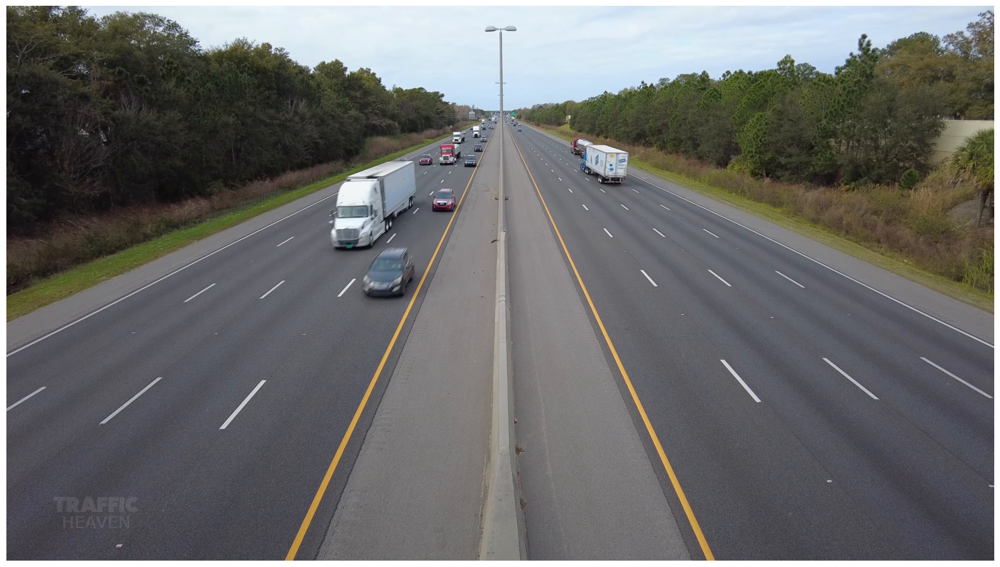

In [9]:
fpath = f"{DEV_CLIPS_DIR}/dev_overhead_heavy_01.mp4"
frame = get_frame(fpath, 111)
print(f"Frame shape {frame.shape}")
show_frame(frame)

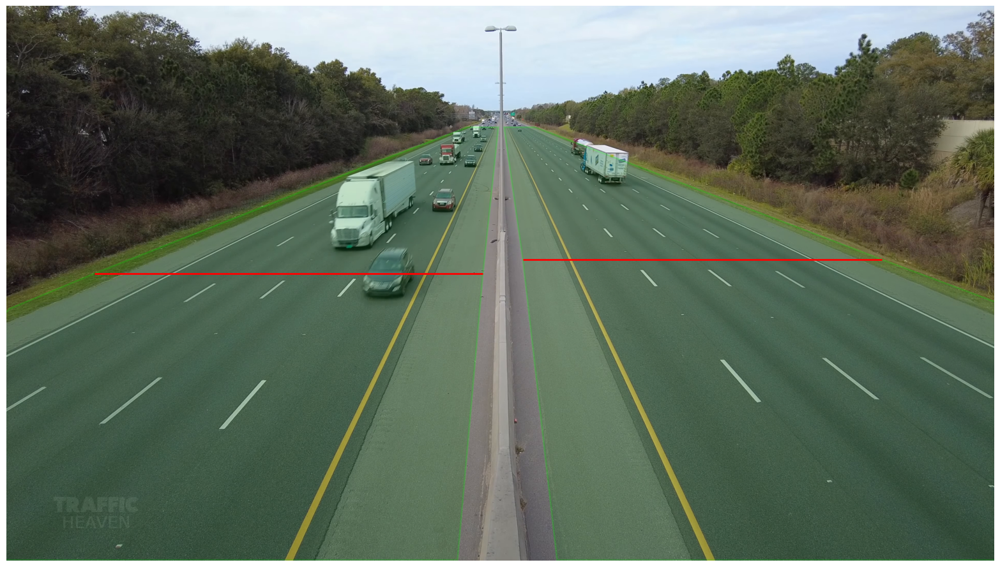

In [10]:
inc_line = [[343, 1042], [1853, 1042]]
inc_zone = [[-1000, 2158], 
            [13, 1179], 
            [343, 1042],
            [1371, 635],
            [1793, 473],
            [1913, 473],
            [1853, 1042],
            [1754, 2158]]

out_line = [(2008, 988), (3405, 988)]
out_zone = [[2141, 2158],
            [2008, 988],
            [1935, 473],
            [2057, 473],
            [3405, 988],
            [6532, 2158]]

lines = [inc_line, out_line]
zones = [inc_zone, out_zone]
draw_lines_and_zone(frame, lines, zones)

### **2.2 Inference at `hys_n=1`**

In [11]:
# Retrieve line and zone configurations
clip_config = CONFIG["dev_overhead_heavy_01.mp4"]
incoming = clip_config["incoming"]
in_line = incoming["line"]
in_zone = incoming["counting_zone"]
outgoing = clip_config["outgoing"]
out_line = outgoing["line"]
out_zone = outgoing["counting_zone"]
dir_labels = incoming["directions"]  

# Load clip and model
model = YOLO("yolov8m.pt")
cap1 = cv2.VideoCapture(f"{DEV_CLIPS_DIR}/dev_overhead_heavy_01.mp4")
fps = round(cap1.get(cv2.CAP_PROP_FPS))

# Create counters
source = "dev_overhead_heavy_01.mp4"
clip1_ctr1 = LineCrossingCounter(source, fps, "incoming", in_line, in_zone, dir_labels, hys_n=1)
clip1_ctr2 = LineCrossingCounter(source, fps, "outgoing", out_line, out_zone, dir_labels, hys_n=1)
clp1_counters1 = (clip1_ctr1, clip1_ctr2)

try:
    clip1_log1, clip1_dets = process_clip(cap=cap1, 
                              out_fname=f"{OUTPUTS_DIR}/dev_overhead_heavy_01_hysn1.mp4", 
                              model=model,
                              counters=clp1_counters1, 
                              save_path=f"{OUTPUTS_DIR}/dev_overhead_heavy_01.pkl", 
                              saved_dets=None,
                              track_file=TRACK_BF60,
                              log_frames=True)
finally: cap1.release()

# with open(f"OUTPUTS_DIR}/dev_overhead_heavy_01_hysn1.pkl", "rb") as f:
#     clip1_saved = pickle.load(f)
    
# clip1_log1, clip1_dets = process_clip(cap=cap1, 
#                           out_fname="OUTPUTS_DIR}/dev_overhead_heavy_01_hysn1.mp4", 
#                           model=None,
#                           counters=clp1_counters1, 
#                           save_path=None, 
#                           saved_dets=clip1_saved,
#                           track_file=TRACK_BF60,
#                           log_frames=True)

Mode: replay of saved detections
(W,H): (3840,2160)
fps: 25.0
Total frames: 3000
200/3000 processed
400/3000 processed
600/3000 processed
800/3000 processed
1000/3000 processed
1200/3000 processed
1400/3000 processed
1600/3000 processed
1800/3000 processed
2000/3000 processed
2200/3000 processed
2400/3000 processed
2600/3000 processed
2800/3000 processed
3000/3000 processed
Total unique IDs: 427
Duration: 262.5s
FPS: 11.4


In [12]:
line_ids = ["incoming", "outgoing"]
true_totals = [153, 99]
sys_totals = [159, 102]
phant_counts = [10, 4]
misses = [4, 1]
df_scores = get_scores(line_ids, true_totals, sys_totals, phant_counts, misses)
df_scores

,true_total,sys_total,phantoms,misses,net_count_err,gross_error_rate
incoming,153,159,10,4,0.039,0.092
outgoing,99,102,4,1,0.030,0.051
total,252,261,14,5,0.036,0.075


### **2.3 Measuring M Without Relying Fully on `span`**

Up to this point, we used `span` (last frame − first frame + 1) to distinguish genuinely fast vehicles from flickering tracks. Our initial assessment was that a real vehicle should be seen on every frame past crossing, but it turns out, this is not the case for two reasons:

- **ID replacement.** A vehicle whose ID is replaced two or three frames after crossing will have a short `span`, even though it’s still a real crossing. We cannot filter these out when choosing M, because if we do, they will not be counted.

- **Our hysteresis mechanism doesn’t use span.** Hysteresis counts sightings on the new side and does not reset if the detection temporarily drops out. It will keep incrementing `self.tentative_crossed[track_id]["count"]` so long as the track's box keep appearing (e.g., after dropping out temporarily). 

The modified `get_span` method of `FrameLogger` (from the previous `counting_analysis` notebook) counts how many times a vehicle is seen on the side of the counting line it ends up on after crossing (positive for incoming, negative for outgoing). But it only counts a vehicle if its previous sighting was on the other side of the line, which means it actually crossed. A track whose first sighting is already on the crossed side is not included. We still check the lowest counts in the video. If a real vehicle crossed, its count is used for M, even if its ID was lost right after. **M comes only from real crossings**, including vehicles whose ID was lost right after. The false tracks that crossed, such as duplicate boxes and box jitter, are what hys_n is meant to filter out, so they’re left out of M.

In [13]:
df = clip1_log1.get_span("incoming", "positive")
df.loc[df["count"] <= 11] 

No. of records: 23321


,track_id,count,first_frm,last_frm,span,contiguous
74,976.0,4,1177,1180,4,True
153,2135.0,4,2675,2696,22,False
121,1618.0,5,1935,1942,8,False
37,419.0,6,711,716,6,True
41,517.0,9,701,709,9,True
18,175.0,9,377,385,9,True
156,2178.0,9,2702,2710,9,True
101,1295.0,10,1546,1556,11,False
17,173.0,10,269,284,16,False
155,2162.0,10,2692,2701,10,True


**Observation:**  While our net count error (3.6%) and gross error rate (7.5%) are already within target (5% for NCE and 10% for GER), incoming GER is 9.2% (10 phantoms, 4 misses), which is close to the limit. Of the 13 incoming crossings with <= 11 sightings (`count`), 8 are phantoms and 5 are real. Setting `hys_n=11` removes 7 phantoms but adds 3 misses. This will still improve incoming GER from 9.2 to 6.5%, which is (3+7)/153. The two fastest real cars (no flicker or gaps past crossing) have exactly 11 `count`. Run code above to generate the output video and confirm these numbers. 

**Note:** The real M is actually 4 (`count=4`), from a vehicle whose track ID disappeared right after crossing. We set `hys_n=11` anyway, on purpose because while it will cause 3 real crossings to miss, it will also removes 7 phantoms, so GER goes down.

**Next step:** Replay the saved detections with incoming `hys_n=11`, then compare its events with run 1's to confirm that exactly 7 phantoms and 3 real crossings were removed.

### **2.4 Inference at `hys_n=11`**

In [14]:
# Retrieve line and zone configurations
clip_config = CONFIG["dev_overhead_heavy_02.mp4"]
incoming = clip_config["incoming"]
in_line = incoming["line"]
in_zone = incoming["counting_zone"]
outgoing = clip_config["outgoing"]
out_line = outgoing["line"]
out_zone = outgoing["counting_zone"]
dir_labels = incoming["directions"]  
cap1 = cv2.VideoCapture(f"{DEV_CLIPS_DIR}/dev_overhead_heavy_01.mp4")
fps = round(cap1.get(cv2.CAP_PROP_FPS))

# Create counters
source = "dev_overhead_heavy_01.mp4"
clip1_ctr1_2 = LineCrossingCounter(source, fps, "incoming", in_line, in_zone, dir_labels, hys_n=11)
clip1_ctr2_2 = LineCrossingCounter(source, fps, "outgoing", out_line, out_zone, dir_labels, hys_n=1)
clp1_counters2 = (clip1_ctr1_2, clip1_ctr2_2)

with open(f"{OUTPUTS_DIR}/dev_overhead_heavy_01_hysn1.pkl", "rb") as f:
    clip1_saved = pickle.load(f)
    
clip1_log2, clip1_dets2 = process_clip(cap=cap1, 
                                       out_fname=f"{DEV_CLIPS_DIR}/dev_overhead_heavy_01_hysn11.mp4", 
                                       model=None,
                                       counters=clp1_counters2, 
                                       save_path=None, 
                                       saved_dets=clip1_saved,
                                       track_file=TRACK_BF60,
                                       log_frames=True)

Mode: replay of saved detections
(W,H): (3840,2160)
fps: 25.0
Total frames: 3000
200/3000 processed
400/3000 processed
600/3000 processed
800/3000 processed
1000/3000 processed
1200/3000 processed
1400/3000 processed
1600/3000 processed
1800/3000 processed
2000/3000 processed
2200/3000 processed
2400/3000 processed
2600/3000 processed
2800/3000 processed
3000/3000 processed
Total unique IDs: 427
Duration: 259.1s
FPS: 11.6


**Check:** Check if the expected 10 tracks that will be ommitted with `hys_n=11` are actually omitted

In [16]:
a = pd.DataFrame(clip1_ctr1.events)   # hys_n=1
b = pd.DataFrame(clip1_ctr1_2.events) # hys_n=11
diff = a.merge(b, how="outer", indicator=True).query("_merge != 'both'")
diff.sort_values("frame_number")

,source_video,line_id,vehicle_id,frame_number,timestamp,direction,class,_merge
17,dev_overhead_heavy_01.mp4,incoming,173.0,269,10.76,B --> A,truck,left_only
18,dev_overhead_heavy_01.mp4,incoming,175.0,377,15.08,B --> A,car,left_only
41,dev_overhead_heavy_01.mp4,incoming,517.0,701,28.04,B --> A,car,left_only
37,dev_overhead_heavy_01.mp4,incoming,419.0,711,28.44,B --> A,car,left_only
74,dev_overhead_heavy_01.mp4,incoming,976.0,1177,47.08,B --> A,truck,left_only
101,dev_overhead_heavy_01.mp4,incoming,1295.0,1546,61.84,B --> A,truck,left_only
121,dev_overhead_heavy_01.mp4,incoming,1618.0,1935,77.40,B --> A,truck,left_only
153,dev_overhead_heavy_01.mp4,incoming,2135.0,2675,107.00,B --> A,car,left_only
155,dev_overhead_heavy_01.mp4,incoming,2162.0,2692,107.68,B --> A,car,left_only
156,dev_overhead_heavy_01.mp4,incoming,2178.0,2702,108.08,B --> A,car,left_only


In [17]:
line_ids = ["incoming", "outgoing"]
true_totals = [153, 99]
sys_totals = [149, 102]
phant_counts = [3, 4]
misses = [7, 1]
df_scores = get_scores(line_ids, true_totals, sys_totals, phant_counts, misses)
df_scores

,true_total,sys_total,phantoms,misses,net_count_err,gross_error_rate
incoming,153,149,3,7,0.026,0.065
outgoing,99,102,4,1,0.030,0.051
total,252,251,7,8,0.004,0.060


### **2.5 Results**

**Results: `dev_overhead_heavy_01`**

See the output video of the second run [here](https://youtu.be/MjQdZz1yxog).

| Run | Change | Line | System | Hand | Phantoms | Misses | NCE | GER |
|---|---|---|---|---|---|---|---|---|
| 1 | Inference, `hys_n=1` on both lines | Incoming | 159 | 153 | 10 | 4 | 3.9% | 9.2% |
| | | Outgoing | 102 | 99 | 4 | 1 | 3.0% | 5.1% |
| | | Total | 261 | 252 | 14 | 5 | 3.6% | 7.5% |
| 2 | Replay, incoming `hys_n=11` | Incoming | 149 | 153 | 3 | 7 | 2.6% | 6.5% |
| | | Outgoing | 102 | 99 | 4 | 1 | 3.0% | 5.1% |
| | | Total | 251 | 252 | 7 | 8 | 0.4% | 6.0% |

**Final settings:** incoming `hys_n=11`, outgoing `hys_n=1`, `cooldown=30`, `track_buffer=60`.  

Both lines are within target. However, relying on the 0.4% total NCE to conclude that run 2 scored well is not recommended. The system undercounted incoming by 4 while outgoing was overcounted by 3, so the two mostly cancel out when added together. For the clip as a whole, GER is the more reliable number because it adds every phantom and every miss instead of letting them offset each other. The two fastest cars (without dropout or flicker) have exactly 11 sightings (`hys_n=11` maintains them in the count).

**Remaining errors:**

- **Phantoms:** Comes mostly from split detections on articulated vehicles. Each track is steady while crossing the line, so `hys_n` can't remove them. This is a detector problem.
- **Misses:** 3 real crossings were removed on purpose by `hys_n=11` (converting them into misses). 

## **3. `dev_overhead_heavy_02`**

**Incoming True Crossings:** 120   
**Outgoing True Crossings:** 90  
**Total True Crossings:** 210

### **3.1 Define Counting and Detection Zone Coordinates**

**Note:** `heavy_02` is from the same original video as `dev_overhead_medium_congest_01` so we can try reusing the previously-defined line and counting zone coordinates.

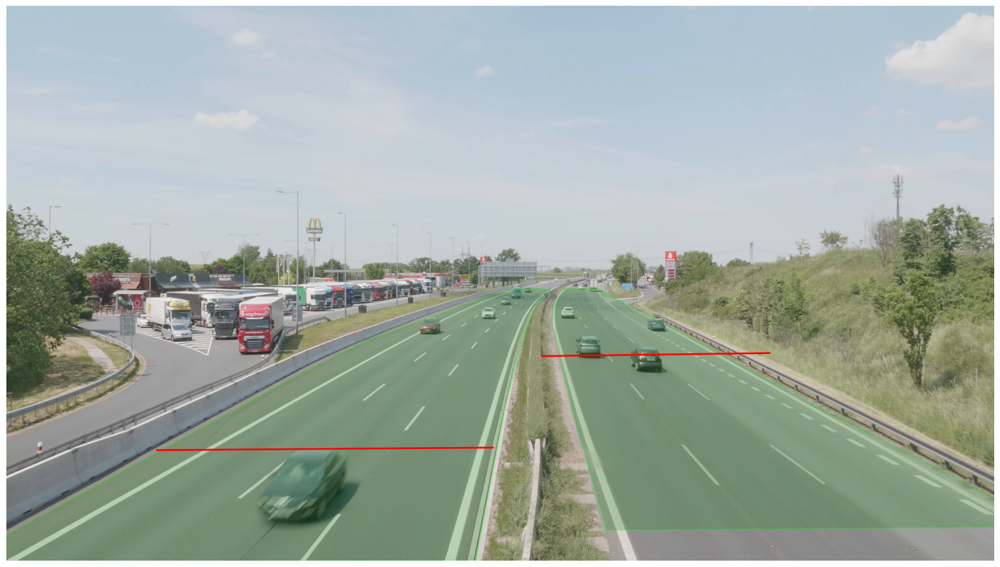

In [9]:
fpath = f"{DEV_CLIPS_DIR}/dev_overhead_heavy_02.mp4"
frame = get_frame(fpath, 111)
 
clip2_inc_line = [[582, 1730], [1895, 1720]]
clip2_inc_zone = [[-200, 2170],    
                  [1155, 1426],  
                  [1399, 1303],  
                  [1640, 1217],  
                  [1860, 1134],  
                  [2005, 1097], 
                  [2117, 1104], 
                  [2053, 1174], 
                  [2034, 1213],  
                  [1940, 1552], 
                  [1826, 2158]]  

clip2_out_line = [[2080, 1364], [2970, 1352]]
clip2_out_zone = [[2334, 2041],  
                  [2208, 1603],  
                  [2134, 1272],  
                  [2129, 1196],  
                  [2134, 1159],
                  [2172, 1100],  
                  [2300, 1102],
                  [2585, 1254], 
                  [3120, 1542],  
                  [3536, 1754],
                  [4050, 2028]] 

clip2_lines = [clip2_inc_line, clip2_out_line]
clip2_zones = [clip2_inc_zone, clip2_out_zone]
draw_lines_and_zone(frame, clip2_lines, clip2_zones)

### **3.2 First Run at `hys_n=1`**

In [10]:
# Retrieve line and zone configurations
clip2_config = CONFIG["dev_overhead_heavy_02.mp4"]
clip2_incoming = clip2_config["incoming"]
clip2_inc_line = clip2_incoming["line"]
clip2_inc_zone = clip2_incoming["counting_zone"]
clip2_outgoing = clip2_config["outgoing"]
clip2_out_line = clip2_outgoing["line"]
clip2_out_zone = clip2_outgoing["counting_zone"]
dir_labels = clip2_incoming["directions"]  

# Load clip and model
model = YOLO("yolov8m.pt")
cap2 = cv2.VideoCapture(f"{DEV_CLIPS_DIR}/dev_overhead_heavy_02.mp4")
cap2fps = round(cap2.get(cv2.CAP_PROP_FPS))

# Create counters
clip2source = "dev_overhead_heavy_02.mp4"
clip2_ctr1 = LineCrossingCounter(clip2source, cap2fps, "incoming", 
                                 clip2_inc_line, clip2_inc_zone, dir_labels, hys_n=1)
clip2_ctr2 = LineCrossingCounter(clip2source, cap2fps, "outgoing", 
                                 clip2_out_line, clip2_out_zone, dir_labels, hys_n=1)
clp2_counters1 = (clip2_ctr1, clip2_ctr2)

try:
    clip2_log1, clip2_dets = process_clip(cap=cap2, 
                              out_fname=f"{OUTPUTS_DIR}/dev_overhead_heavy_02_hysn1.mp4", 
                              model=model,
                              counters=clp2_counters1, 
                              save_path=f"{OUTPUTS_DIR}/dev_overhead_heavy_02.pkl", 
                              saved_dets=None,
                              track_file=TRACK_BF60,
                              log_frames=True)
finally: cap2.release()

# with open(f"{OUTPUTS_DIR}/dev_overhead_heavy_02.pkl", "rb") as f:
#     clip2_saved = pickle.load(f)
    
# clip2_log1, clip2_dets = process_clip(cap=cap2, 
#                                       out_fname=f"{OUTPUTS_DIR}/dev_overhead_heavy_02_hysn1.mp4", 
#                                       model=None,
#                                       counters=clp2_counters1, 
#                                       save_path=None, 
#                                       saved_dets=clip2_saved,
#                                       track_file=TRACK_BF60,
#                                       log_frames=True)

Mode: replay of saved detections
(W,H): (3840,2160)
fps: 24.000074689029116
Total frames: 2892
200/2892 processed
400/2892 processed
600/2892 processed
800/2892 processed
1000/2892 processed
1200/2892 processed
1400/2892 processed
1600/2892 processed
1800/2892 processed
2000/2892 processed
2200/2892 processed
2400/2892 processed
2600/2892 processed
2800/2892 processed
Total unique IDs: 417
Duration: 221.2s
FPS: 13.0


**Note:** `Warning: 2880 saved frames vs 2892 frames in the clip` appeared. Check first the number of frames that was actually decoded to confirm if it is 2880.

In [11]:
_ = cv2.VideoCapture(f"{DEV_CLIPS_DIR}/dev_overhead_heavy_02.mp4")
n = 0
while _.read()[0]:
    n += 1
_.release()
print(n)

2880


In [12]:
line_ids = ["incoming", "outgoing"]
true_totals = [120, 90]
sys_totals = [119, 89]
phant_counts = [0, 0]
misses = [1, 1]
df_scores = get_scores(line_ids, true_totals, sys_totals, phant_counts, misses)
df_scores

,true_total,sys_total,phantoms,misses,net_count_err,gross_error_rate
incoming,120,119,0,1,0.008,0.008
outgoing,90,89,0,1,0.011,0.011
total,210,208,0,2,0.010,0.010


### **3.3 Results for `dev_overhead_heavy_02`**

See the exact clip [here](https://youtu.be/9IsycaoHeZw).

| Run | Change | Line | System | Hand | Phantoms | Misses | NCE | GER |
|---|---|---|---|---|---|---|---|---|
| 1 | Inference, `hys_n=1` on both lines | Incoming | 119 | 120 | 0 | 1 | 0.8% | 0.8% |
| | | Outgoing | 89 | 90 | 0 | 1 | 1.1% | 1.1% |
| | | Total | 208 | 210 | 0 | 2 | 1.0% | 1.0% |

**Final settings:** incoming `hys_n=1`, outgoing `hys_n=1`, `cooldown=30`, `track_buffer=60`.

Best clip so far. Both lines are well within target after the first run, so we left the settings as they are. There were no phantoms on either line, so hysteresis had nothing to remove. **NCE and GER are exactly the same here because every error is a miss, so there is nothing for the system total to cancel out.**

**Remaining errors:**
- **Incoming miss:** a truck occluded by another truck (around 0:00:44). Its box disappears right as it crosses the line, so the crossing is never seen.
- **Outgoing miss:** a smaller vehicle completely hidden behind a truck (0:00:30). It is never detected at all, so no setting could have counted it.

**Both misses come from vehicles being hidden from this camera, not from the counting logic.**

## **4. `dev_roadside_heavy_congest_01`**



### **4.1 Define Counting and Detection Zone Coordinates**

Frame shape (1080, 1920, 3)


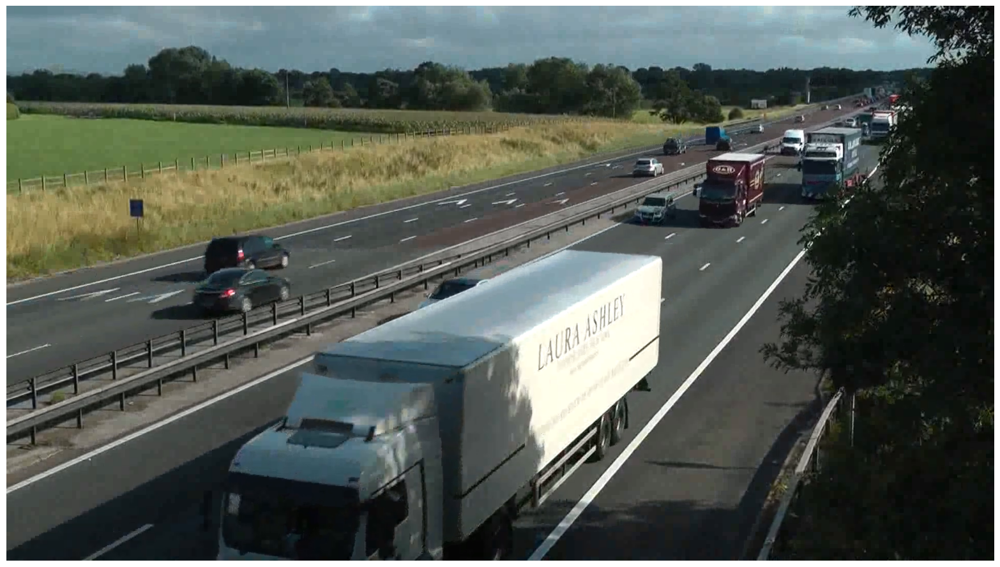

In [9]:
fpath = f"{DEV_CLIPS_DIR}/dev_roadside_heavy_congest_01.mp4"
frame = get_frame(fpath, 111)
print(f"Frame shape {frame.shape}")
show_frame(frame)

**Note:** We can look back at this previously-generated [output video](youtu.be/NTVVJdfpCCM) of the clip (with detection boxes and confidence scores). It shows where vehicles are detected reliably, and the line should go in one of those areas.

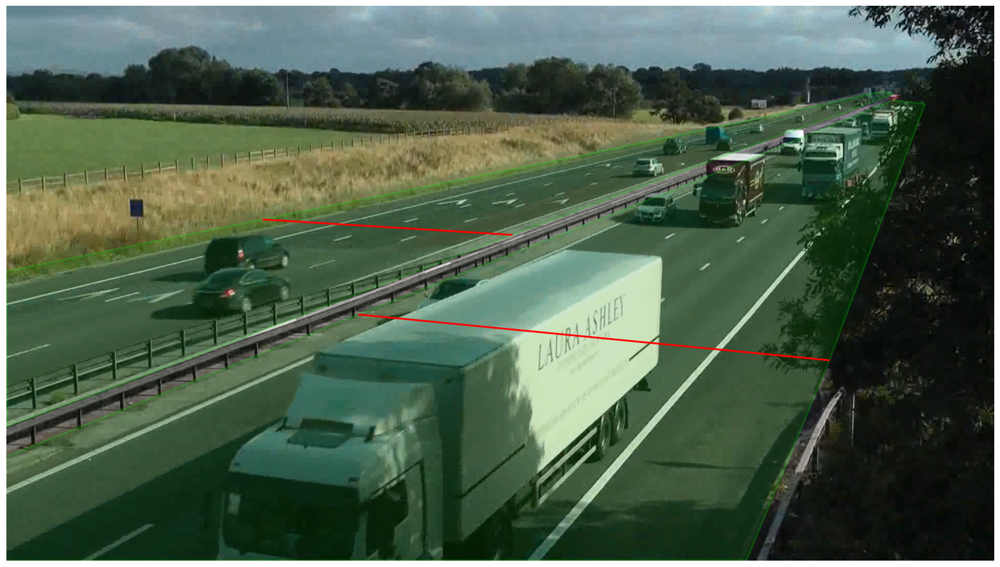

In [10]:
clip3_out_line = [[498, 416], [984, 446]]
clip3_out_zone = [[0.4, 517], 
                  [498, 416], 
                  [1125, 290],
                  [1562, 198],
                  [1700, 167],
                  [1725, 171],
                  [1633, 207],
                  [1509, 250],
                  [984, 446],
                  [191, 749],
                  [2, 818]]

clip3_inc_line = [[684, 601], [1600, 690]]
clip3_inc_zone = [[-500, 1080],
                  [684, 601],
                  [1341, 341],
                  [1724, 184],
                  [1786, 191],
                  [1600, 690],
                  [1439, 1079]]

clip3_lines = [clip3_out_line, clip3_inc_line]
clip3_zones = [clip3_out_zone, clip3_inc_zone]
draw_lines_and_zone(frame, clip3_lines, clip3_zones)

### **4.2 First Run at `hys_n=1`**

In [11]:
# Retrieve line and zone configurations
clip3_config = CONFIG["dev_roadside_heavy_congest_01.mp4"]
clip3_incoming = clip3_config["incoming"]
clip3_inc_line = clip3_incoming["line"]
clip3_inc_zone = clip3_incoming["counting_zone"]
clip3_outgoing = clip3_config["outgoing"]
clip3_out_line = clip3_outgoing["line"]
clip3_out_zone = clip3_outgoing["counting_zone"]
dir_labels = clip3_incoming["directions"]  

# Load clip and model
model = YOLO("yolov8m.pt")
cap3 = cv2.VideoCapture(f"{DEV_CLIPS_DIR}/dev_roadside_heavy_congest_01.mp4")
cap3fps = round(cap3.get(cv2.CAP_PROP_FPS))

# Create the counters
clip3source = "dev_roadside_heavy_congest_01.mp4"
clip3_ctr1 = LineCrossingCounter(clip3source, cap3fps, "incoming", 
                                 clip3_inc_line, clip3_inc_zone, 
                                 dir_labels, hys_n=1)
clip3_ctr2 = LineCrossingCounter(clip3source, cap3fps, "outgoing", 
                                 clip3_out_line, clip3_out_zone, 
                                 dir_labels, hys_n=1)
clp3_counters1 = (clip3_ctr1, clip3_ctr2)

try:
    clip3_log1, clip3_dets = process_clip(cap=cap3, 
                                          out_fname=f"{OUTPUTS_DIR}/dev_roadside_heavy_congest_01_hysn1.mp4", 
                                          model=model,
                                          counters=clp3_counters1, 
                                          save_path=f"{OUTPUTS_DIR}/dev_roadside_heavy_congest_01.pkl", 
                                          saved_dets=None,
                                          track_file=TRACK_BF60,
                                          log_frames=True)
finally: cap3.release()

with open(f"{DEV_CLIPS_DIR}/dev_roadside_heavy_congest_01.pkl", "rb") as f:
    clip3_saved = pickle.load(f)
    
# clip3_log1, clip3_dets = process_clip(cap=cap3, 
#                           out_fname=f"{OUTPUTS_DIR}/dev_roadside_heavy_congest_01_hysn1.mp4", 
#                           model=None,
#                           counters=clp3_counters1, 
#                           save_path=None, 
#                           saved_dets=clip3_saved, 
#                           track_file=TRACK_BF60,
#                           log_frames=True)

Mode: replay of saved detections
(W,H): (1920,1080)
fps: 25.0
Total frames: 2301
200/2301 processed
400/2301 processed
600/2301 processed
800/2301 processed
1000/2301 processed
1200/2301 processed
1400/2301 processed
1600/2301 processed
1800/2301 processed
2000/2301 processed
2200/2301 processed
Total unique IDs: 366
Duration: 45.6s
FPS: 49.9


In [12]:
line_ids = ["incoming", "outgoing"]
true_totals = [75, 122]
sys_totals = [71, 118]
phant_counts = [1, 0]
misses = [5, 4] 
df_scores = get_scores(line_ids, true_totals, sys_totals, phant_counts, misses)
df_scores

,true_total,sys_total,phantoms,misses,net_count_err,gross_error_rate
incoming,75,71,1,5,0.053,0.080
outgoing,122,118,0,4,0.033,0.033
total,197,189,1,9,0.041,0.051


8 of the misses came from vehicles being occluded, with one case of merged detection causing a miss at 0:00:58. On incoming, all 5 misses were vehicles hidden behind large trucks, and they are mostly in the outermost lane on the left. On outgoing, 2 vehicles were hidden behind a truck in the incoming lanes, 1 was hidden by a van in the same lane, and 1 was merged with a truck into a single box. 

### **4.3 Move the Counting Lines Closer to the Camera**

The lanes appear further apart when closer to the camera, so vehicles should overlap less and are less likely to be occluded or merged as they cross paths. We move the incoming line as close to the camera as the reliable detection zone allows, while keeping the same line direction and angle (a translation + length shift). The outgoing line stays where it is, since it already meets the targets (< 5% NCE as opposed to the incoming line).

**Note:** We had to rely on this earlier [detection video](https://www.youtube.com/watch?v=NTVVJdfpCCM) to verify if closer-to-camera detections tend to have higher confidence scores for this type of camera angle (they do as expected). To ensure that future annotated outputs will also display confidence scores, in addition to the signs, track Ids, and class names, we will also update the `draw_annotations` function in Section 0.

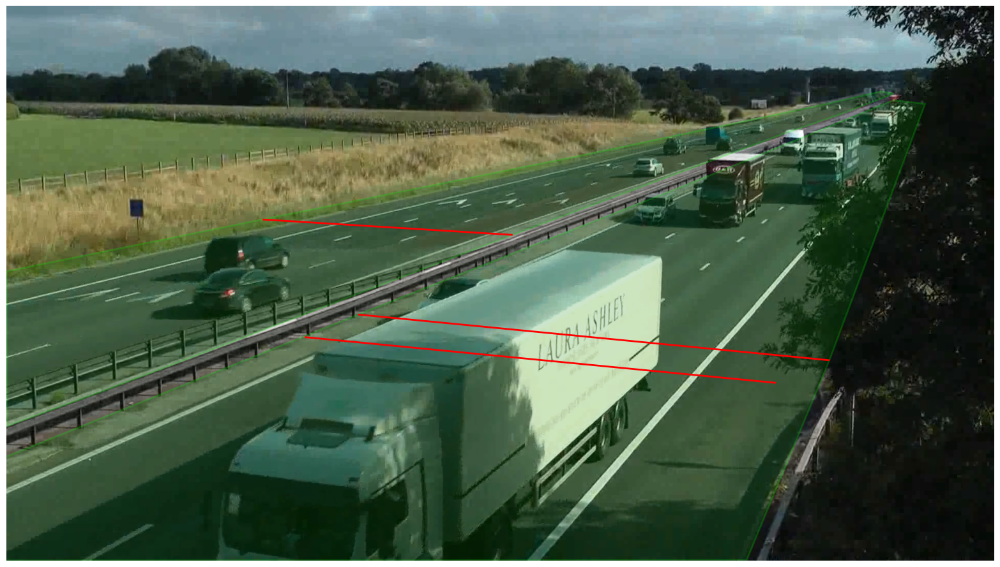

In [13]:
clip3_config = CONFIG["dev_roadside_heavy_congest_01.mp4"]
clip3_incoming = clip3_config["incoming"]
clip3_outgoing = clip3_config["outgoing"]

clip3_inc_line = [[684, 601], [1600, 690]]
clip3_inc_zone = clip3_incoming["counting_zone"]
clip3_out_line = [[498, 416], [984, 446]]
clip3_out_zone = clip3_outgoing["counting_zone"]

clip3_inc_new = [[580, 645], [1496, 734]]

clip3_lines = [clip3_out_line, clip3_inc_line, clip3_inc_new]
clip3_zones = [clip3_out_zone, clip3_inc_zone]
draw_lines_and_zone(frame, clip3_lines, clip3_zones)

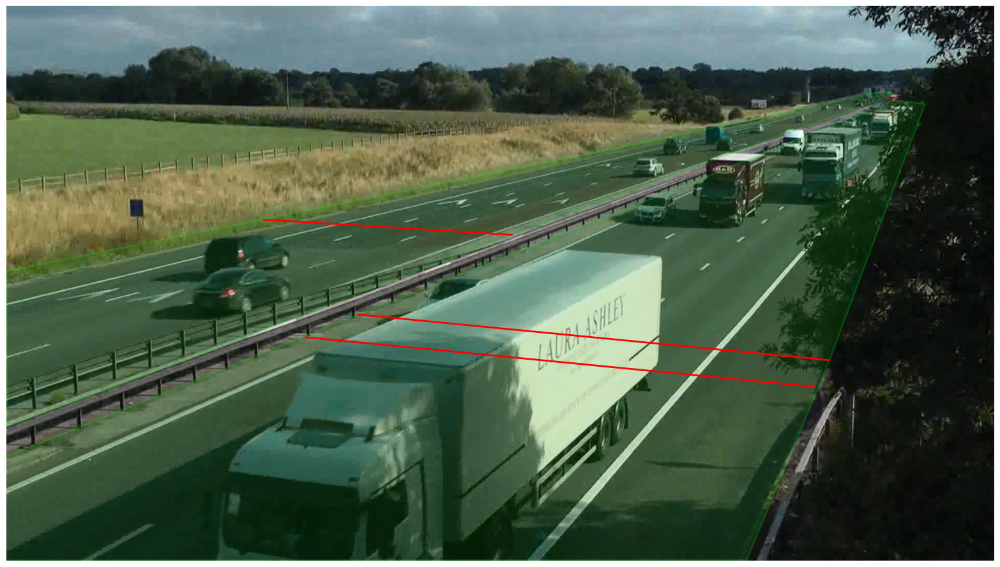

In [14]:
clip3_inc_new = scale_line(clip3_inc_new, k=1.085, anchor="start")

clip3_lines = [clip3_out_line, clip3_inc_line, clip3_inc_new]
clip3_zones = [clip3_out_zone, clip3_inc_zone]

draw_lines_and_zone(frame, clip3_lines, clip3_zones)

In [27]:
dir_labels = clip3_incoming["directions"]  
model = YOLO("yolov8m.pt")
cap3 = cv2.VideoCapture(f"{DEV_CLIPS_DIR}/dev_roadside_heavy_congest_01.mp4")
cap3fps = round(cap3.get(cv2.CAP_PROP_FPS))

# Create the counters
clip3source = "dev_roadside_heavy_congest_01.mp4"
clip3_ctr1_2 = LineCrossingCounter(clip3source, cap3fps, "incoming", 
                                 clip3_inc_new, clip3_inc_zone, 
                                 dir_labels, hys_n=1)
clip3_ctr2_2 = LineCrossingCounter(clip3source, cap3fps, "outgoing", 
                                 clip3_out_line, clip3_out_zone, 
                                 dir_labels, hys_n=1)
clp3_counters2 = (clip3_ctr1_2, clip3_ctr2_2)

with open(f"{DEV_CLIPS_DIR}/dev_roadside_heavy_congest_01.pkl", "rb") as f:
    clip3_saved = pickle.load(f)
    
clip1_log2, clip1_dets = process_clip(cap=cap3, 
                          out_fname=f"{OUTPUTS_DIR}/dev_roadside_heavy_congest_01_adj_incline.mp4", 
                          model=None,
                          counters=clp3_counters2, 
                          save_path=None, 
                          saved_dets=clip3_saved, 
                          track_file=TRACK_BF60,
                          log_frames=True)

Mode: replay of saved detections
(W,H): (1920,1080)
fps: 25.0
Total frames: 2301
200/2301 processed
400/2301 processed
600/2301 processed
800/2301 processed
1000/2301 processed
1200/2301 processed
1400/2301 processed
1600/2301 processed
1800/2301 processed
2000/2301 processed
2200/2301 processed
Total unique IDs: 366
Duration: 47.2s
FPS: 48.2


**Check Discrepancies:** Similar to what we did in the first clip (`dev_overhead_heavy_01`), we compare the incoming line's `events` of the old and new line positions, since the same vehicles now cross at a different frame. `left_only` rows (`_merge` column) are vehicles counted only at the old line, and `right_only` rows are vehicles counted only at the new line.

In [21]:
a = pd.DataFrame(clip3_ctr1.events)   # hys_n=1
b = pd.DataFrame(clip3_ctr1_2.events) # hys_n=1 but new line position
diff = a.merge(b, on=["vehicle_id", "direction"], how="outer", indicator=True).query("_merge != 'both'")
diff.sort_values("vehicle_id")

,source_video_x,line_id_x,vehicle_id,frame_number_x,timestamp_x,direction,class_x,source_video_y,line_id_y,frame_number_y,timestamp_y,class_y,_merge
1,NaN,NaN,4.0,NaN,NaN,B --> A,NaN,dev_roadside_heavy_congest_01.mp4,incoming,1.0,0.04,car,right_only
7,NaN,NaN,101.0,NaN,NaN,B --> A,NaN,dev_roadside_heavy_congest_01.mp4,incoming,133.0,5.32,car,right_only
16,NaN,NaN,296.0,NaN,NaN,B --> A,NaN,dev_roadside_heavy_congest_01.mp4,incoming,281.0,11.24,truck,right_only
25,NaN,NaN,483.0,NaN,NaN,B --> A,NaN,dev_roadside_heavy_congest_01.mp4,incoming,499.0,19.96,car,right_only
33,NaN,NaN,629.0,NaN,NaN,B --> A,NaN,dev_roadside_heavy_congest_01.mp4,incoming,632.0,25.28,car,right_only
64,dev_roadside_heavy_congest_01.mp4,incoming,1481.0,1894.0,75.76,B --> A,car,NaN,NaN,NaN,NaN,NaN,left_only
68,NaN,NaN,1625.0,NaN,NaN,B --> A,NaN,dev_roadside_heavy_congest_01.mp4,incoming,1681.0,67.24,truck,right_only
72,dev_roadside_heavy_congest_01.mp4,incoming,1686.0,1801.0,72.04,B --> A,car,NaN,NaN,NaN,NaN,NaN,left_only
73,NaN,NaN,1783.0,NaN,NaN,B --> A,NaN,dev_roadside_heavy_congest_01.mp4,incoming,1919.0,76.76,car,right_only
74,dev_roadside_heavy_congest_01.mp4,incoming,1870.0,2270.0,90.80,B --> A,car,NaN,NaN,NaN,NaN,NaN,left_only


### **4.4 Results**

See the output clip [here](https://youtu.be/hzDHJhARmZY).

- The new run has 71 - 5 (left_only) + 7 (right_only) = 73 events
- ID 4 was included because the counting line is now closer to the camera
- IDs 101, 296, and 629 are three (out of 5) of the old line misses that were now counted in the adjusted line
- IDs 483 and 1625 are phantom counts that made it into the new line
- ID 1481 is a new miss that was occluded before it is counted by the new line
- ID 1686 (old) and 1783 (new) is the same vehicle
- IDs 1870, 1888, and 2079 are vehicles at the end of the clip that did not make it on the new line position

**Incoming Tally After Moving the Line:**

|  | Old line | New line | Notes |
|---|---|---|---|
| True total | 75 | 73 | +1 (ID 4), −3 (IDs 1870, 1888, 2079) |
| System | 71 | 73 | −5 events counted exclusively at the old line, +7 counted exclusively at the new line |
| Phantoms | 1 | 3 | The original phantom is still counted, plus IDs 483 and 1625 |
| Misses | 5 | 3 | 3 recovered (IDs 101, 296, 629), 2 still missed, plus 1 new miss (ID 1481) |

**The tally balances:** phantoms − misses = 3 − 3 = 0, and system − true = 73 − 73 = 0.   
*When the system total and true total is equal, misses and phantoms have to be equal be equal as well and cancel out.*

| Incoming | NCE | GER |
|---|---|---|
| Old line | 4/75 = 5.3% | 6/75 = 8.0% |
| New line | 0/73 = 0.0% | 6/73 = 8.2% |

The 0% NCE comes entirely from 3 phantoms and 3 misses cancelling out. GER made a small increase. Moving the line recovered 3 misses but added 2 phantoms and 1 new miss, so the number of errors stayed the same. Moving the incoming line decreased its NCE under 5% (which was the goal). However, it did not really make the counting more accurate. It just changed which errors happen. 

In [23]:
line_ids = ["incoming", "outgoing"]
true_totals = [73, 122]
sys_totals = [73, 118]
phant_counts = [3, 0]
misses = [3, 4] 
df_scores = get_scores(line_ids, true_totals, sys_totals, phant_counts, misses)
df_scores

,true_total,sys_total,phantoms,misses,net_count_err,gross_error_rate
incoming,73,73,3,3,0.000,0.082
outgoing,122,118,0,4,0.033,0.033
total,195,191,3,7,0.021,0.051


With outgoing unchanged, the clip totals are 191 against 195, with 3 phantoms and 7 misses. GER is the same as before the move but NCE decreased from 4.1% to 2.1% so we will keep this new incoming line coordinates.

In [24]:
clip3_inc_new

[[580, 645], [1574, 742]]

## **5. Summary Performance of All 4 Dev Clips**

Final results for each dev clip after tuning. Each line is listed separately, as NCE alone can hide errors that cancel out.

| Clip | `hys_n` (in / out) | Line | System | Hand | Phantoms | Misses | NCE | GER |
|---|---|---|---|---|---|---|---|---|
| `dev_overhead_medium_congest_01` | 5 / 4 | Incoming | 83 | 81 | 2 | 0 | 2.5% | 2.5% |
| | | Outgoing | 70 | 71 | 0 | 1 | 1.4% | 1.4% |
| | | Total | 153 | 152 | 2 | 1 | 0.7% | 2.0% |
| `dev_overhead_heavy_01` | 11 / 1 | Incoming | 149 | 153 | 3 | 7 | 2.6% | 6.5% |
| | | Outgoing | 102 | 99 | 4 | 1 | 3.0% | 5.1% |
| | | Total | 251 | 252 | 7 | 8 | 0.4% | 6.0% |
| `dev_overhead_heavy_02` | 1 / 1 | Incoming | 119 | 120 | 0 | 1 | 0.8% | 0.8% |
| | | Outgoing | 89 | 90 | 0 | 1 | 1.1% | 1.1% |
| | | Total | 208 | 210 | 0 | 2 | 1.0% | 1.0% |
| `dev_roadside_heavy_congest_01` | 1 / 1 | Incoming | 73 | 73 | 3 | 3 | 0.0% | 8.2% |
| | | Outgoing | 118 | 122 | 0 | 4 | 3.3% | 3.3% |
| | | Total | 191 | 195 | 3 | 7 | 2.1% | 5.1% |

All four clips meet the targets (NCE ≤ 5% and GER ≤ 10%) both for each line and for each whole clip. The highest GER is 8.2% on the roadside clip's incoming line, where the 0% NCE comes from 3 phantoms cancelling out 3 misses. Note that there are no aggregate metrics across all four clips because the metrics are reported per clip and not averaged into one headline number. This means that, *at least for now*, there is not a single figure meant to sum up the whole system at a glance (e.g., "the system is 98% accurate").

The errors that remain come from the detector and footage limitations, not the counting logic:

- **Phantoms:** mostly vehicles with trailers detected as two or three boxes, each of which crosses the line.
- **Misses:** mostly vehicles hidden behind large trucks, especially in far lanes on the roadside clip. Also, there are at least two cases of undetected motorcycles and one wagon merged with a truck into a single box (this is the only observed case of a merged detection causing a miss).

**Our targets hold up against published ones.** 

For instance, a 5% NCE target matches the [Virginia DOT acceptance framework](https://vtrc.virginia.gov/reports/all-reports/26-r53/)  
In addition, gross error rate is stricter than the WAPE metric agencies use:  
- WAPE adds up the error of each time interval (for example, every 15 minutes), so a phantom and a miss in the same interval still cancel each other out. 
- Gross error rate, on the other hand, counts every phantom and every miss in the numerator, so nothing cancels.

We are now moving to evaluation. The system is frozen from this point. We will use the same detector, tracker and counting logic, with only the lines, zones, `hys_n` and `cooldown` set for each new clip. Lines and zones on the eval clips are placed using the same rules as on the dev clips, without looking at the hand counts, and nothing will be changed after seeing the results.